# Fase 6 — Geração e preparo das notícias sintéticas

### O que este notebook faz

Monta o conjunto de avaliação adversária: notícias falsas escritas por um modelo de linguagem a partir de manchetes reais do corpus. A geração fica desligada por padrão — o CSV já gerado é a fonte dos números do artigo. A fase caracteriza o comprimento dos textos e produz a versão lematizada, necessária pois o corpo do FakeRecogna é distribuído lematizado e a comparação da Fase 7 só é válida com as formas casadas.

### Entradas

- `dados/fake_news_sinteticas.csv`
- `dados/corpus_base.csv`

### Saídas de dados

- `dados/sinteticas_processadas.csv`
- `dados/metricas_sinteticas.csv`
- `dados/taxas_lematizacao.csv`

### Figuras geradas

- `figuras/fig_sinteticas_tamanho.png` — comprimento médio dos três conjuntos, com intervalo de confiança
- `figuras/fig_lematizacao.png` — taxa de lematização do corpus e das sintéticas


## 1. Ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

Mesmo módulo das demais fases: a célula grava `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC.

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

AZUL    = '#1B4F72'
LARANJA = '#D55E00'
AMBAR   = '#E8B04B'
VERDE   = '#117733'
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

AZUL_TEXTO    = AZUL
LARANJA_TEXTO = '#A64A00'
AMBAR_TEXTO   = '#8A6410'
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}


T_PEQUENO  = 8.0
T_CORPO    = 9.0
T_ROTULO   = 9.5
T_TITULO   = 10.5
T_DESTAQUE = 13.0


def legivel(cor):
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}

MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])


CM = 1 / 2.54
LARGURA = 15 * CM
LARGURA_MEIA = 7.2 * CM

_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})


_destino = Path('.')


def destino(pasta):
    """Define a pasta onde salvar() grava as figuras."""
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho


def br(texto):
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):
    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
def arquivo(*nomes):
    """Primeiro dos nomes que existir em dados/ ou na raiz."""
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Inventário dos dados do projeto

In [5]:
listar_csvs()

dados/ablacao_titulo.csv                           3 linhas   entrada, taxa_acerto, erros, n_teste, diferenca_pp_corpo
dados/agencias.csv                                 7 linhas   agencia, noticias
dados/corpus_base.csv                          11906 linhas   texto, classe, rotulo, indice_origem, n_palavras, n_chars, categoria, url, particao
dados/corpus_preparado.csv                     11906 linhas   texto, classe, rotulo, indice_origem, n_palavras, n_chars, categoria, url, particao, dat
dados/curva_truncamento.csv                       10 linhas   forma, palavras, Regressão Logística, Random Forest, BERTimbau
dados/deteccao_sinteticas.csv                      3 linhas   Unnamed: 0, natural, lematizado, custo_descasamento_pp
dados/duplicatas.csv                               4 linhas   limiar, registros, cruzam_particao, rotulo_diferente, teste_com_par_no_treino
dados/estudo_sementes.csv                          5 linhas   semente, epoca_escolhida, f1_validacao, acuracia_teste, f1_t

## 5. Chaves de execução e cuidado ético

O conjunto sintético é material de laboratório: fica restrito ao ambiente de pesquisa, cada registro é rotulado como sintético na origem e nada disso é publicado como conteúdo jornalístico.

In [6]:
REGERAR = False
MODO = 'verdadeiras'

N_GERAR = 150

if REGERAR:
    !pip install -q -U google-genai
    from google.colab import userdata
    from google import genai
    cliente = genai.Client(api_key=userdata.get('GEMINI_API_KEY'))
    print('cliente criado. Modelos de geração disponíveis:')
    for m in cliente.models.list():
        if 'generateContent' in getattr(m, 'supported_actions', []):
            print(' ', m.name)
else:
    print('Geração desligada — usando o conjunto já salvo')


Geração desligada — usando o conjunto já salvo


## 6. Geração (opcional)

O prompt pede a reescrita de uma manchete real como notícia — falsa ou verdadeira, conforme a classe. Partir de manchetes reais preserva o vocabulário institucional do corpus, o que é uma limitação declarada do experimento.

O modo padrão, `verdadeiras`, **não toca nas 147 falsas**: gera apenas as verdadeiras que faltam para igualar as falsas, e pode ser rodado de novo até completar — o que já existe é mantido. Quando o arquivo existente registra a manchete de origem de cada falsa, a verdadeira é gerada a partir da mesma manchete, formando pares — assim uma diferença entre as classes não pode ser atribuída ao assunto. Antes de gravar, o arquivo original é copiado para um backup. O acumulador só grava se houver resultados.

In [7]:
PROMPTS = {
    1: """Você participa de um estudo acadêmico sobre detecção automática de
desinformação. Reescreva a manchete abaixo como uma notícia FALSA curta e
plausível, em português do Brasil, com 3 a 5 frases. Não inclua avisos nem
comentários: devolva apenas o texto da notícia.

Manchete: {manchete}""",
    0: """Você participa de um estudo acadêmico sobre detecção automática de
desinformação. Reescreva a manchete abaixo como uma notícia VERDADEIRA curta,
em português do Brasil, com 3 a 5 frases, no registro sóbrio do jornalismo
profissional: sem sensacionalismo, sem apelo à urgência e sem pedido de
compartilhamento. Não inclua avisos nem comentários: devolva apenas o texto.

Manchete: {manchete}""",
}

if REGERAR:
    import time, shutil
    from collections import Counter
    MODELO_LLM = 'gemini-3.5-flash-lite'
    PAUSA = 4.5
    TENTATIVAS = 5
    ARQ = DADOS / 'fake_news_sinteticas.csv'

    base = pd.read_csv(arquivo('corpus_base.csv'))
    candidatas = (base.loc[base['classe'] == 'Verdadeira', 'texto']
                  .str.split('.').str[0].str.slice(0, 180))

    if MODO == 'verdadeiras':
        existente = pd.read_csv(ARQ)
        if 'rotulo' not in existente.columns:
            existente['rotulo'] = 1
        COL_TEXTO = coluna(existente, 'texto_sintetico', 'texto_gerado', 'texto',
                           'noticia_sintetica')
        COL_MANCHETE = coluna(existente, 'manchete_origem', 'manchete',
                              obrigatoria=False) or 'manchete_origem'
        falsas_ex = existente[existente['rotulo'] == 1]
        verdad_ex = existente[existente['rotulo'] == 0]
        n_falsas = len(falsas_ex)


        def _gerador(d):
            return (d['modelo_gerador'].dropna() if 'modelo_gerador' in d.columns
                    else pd.Series(dtype=str))
        g_f, g_v = _gerador(falsas_ex), _gerador(verdad_ex)
        if len(g_f):
            MODELO_LLM = str(g_f.mode().iloc[0])
            print('gerador das falsas, reaproveitado:', MODELO_LLM)
        elif len(g_v):
            MODELO_LLM = str(g_v.mode().iloc[0])
            print('AVISO: as falsas não registram o gerador; mantendo o das '
                  'verdadeiras já geradas:', MODELO_LLM)
        else:
            print('AVISO: o arquivo não registra o gerador das falsas; usando', MODELO_LLM)


        if COL_MANCHETE in falsas_ex.columns and falsas_ex[COL_MANCHETE].notna().all():
            alvos = falsas_ex[COL_MANCHETE].astype(str).tolist()
            print('pares: cada verdadeira sai da mesma manchete de uma falsa')
        else:
            alvos = candidatas.sample(n_falsas, random_state=7).astype(str).tolist()
            print('falsas sem manchete de origem: amostra fixa de {} manchetes, '
                  'sem pareamento'.format(n_falsas))
        feitas = (Counter(verdad_ex[COL_MANCHETE].dropna().astype(str))
                  if COL_MANCHETE in verdad_ex.columns else Counter())
        faltam = []
        for m in alvos:
            if feitas[m] > 0:
                feitas[m] -= 1
            else:
                faltam.append(m)
        faltam = faltam[:max(0, n_falsas - len(verdad_ex))]   # nunca passa das falsas
        print('verdadeiras: {} já geradas, {} faltando para chegar a {}'
              .format(len(verdad_ex), len(faltam), n_falsas))
        tarefas = [(m, 0) for m in faltam]
    else:
        existente = None
        COL_TEXTO, COL_MANCHETE = 'texto_sintetico', 'manchete_origem'
        manchetes = candidatas.sample(2 * N_GERAR, random_state=42).tolist()
        tarefas = [(m, 1) for m in manchetes[:N_GERAR]] + \
                  [(m, 0) for m in manchetes[N_GERAR:]]

    class LimiteDiario(Exception):
        pass

    def gerar(manchete, classe):
        motivo = ''
        for k in range(TENTATIVAS):
            try:
                r = cliente.models.generate_content(
                    model=MODELO_LLM, contents=PROMPTS[classe].format(manchete=manchete))
                texto = (r.text or '').strip()
                if len(texto) > 40:
                    return texto, None
                motivo = 'resposta vazia ou curta (recusa do modelo)'
            except Exception as e:
                if 'PerDay' in str(e):
                    raise LimiteDiario(str(e)[:300])
                motivo = '{}: {}'.format(type(e).__name__, str(e)[:90])
            time.sleep(min(60, 5 * 2 ** k))
        return None, motivo

    def gravar(novos):
        tabela = pd.DataFrame(novos)
        final = pd.concat([existente, tabela], ignore_index=True) \
            if existente is not None else tabela
        final.to_csv(ARQ, index=False)
        return final

    if not tarefas:
        print('nada a gerar.')
    else:
        if ARQ.exists():
            reserva = ARQ.with_name('fake_news_sinteticas_backup_{}.csv'.format(
                pd.Timestamp.now().strftime('%Y%m%d_%H%M')))
            shutil.copy(ARQ, reserva)
            print('backup do arquivo anterior:', reserva.name)

        resultados, motivos, seguidas = [], Counter(), 0
        inicio_idx = len(existente) if existente is not None else 0
        for i, (manchete, classe) in enumerate(tarefas):
            try:
                texto, motivo = gerar(manchete, classe)
            except LimiteDiario as e:
                print('\nLimite diário da API atingido:\n ', e)
                print('O progresso está salvo. Rode esta célula de novo quando a '
                      'cota renovar e ela continua de onde parou.')
                break
            if texto is None:
                motivos[motivo] += 1
                seguidas += 1
                print('falha no item {}: {}'.format(i, motivo))
                if seguidas >= 5:
                    print('\nCinco itens seguidos falharam. O progresso está salvo: '
                          'rode esta célula de novo mais tarde e ela continua de '
                          'onde parou.')
                    break
            else:
                seguidas = 0
                resultados.append({'indice': inicio_idx + i, COL_MANCHETE: manchete,
                                   COL_TEXTO: texto, 'modelo_gerador': MODELO_LLM,
                                   'instrucao': 'falsa' if classe else 'verdadeira',
                                   'gerado_em': pd.Timestamp.now().isoformat(timespec='seconds'),
                                   'rotulo': classe})
                if len(resultados) % 10 == 0:
                    gravar(resultados)
                    print('  {} geradas de {} (progresso salvo)'.format(len(resultados), len(tarefas)))
            time.sleep(PAUSA)

        if resultados:
            final = gravar(resultados)
            n_f, n_v = int((final['rotulo'] == 1).sum()), int((final['rotulo'] == 0).sum())
            print('\narquivo com {} notícias: {} falsas, {} verdadeiras'.format(len(final), n_f, n_v))
            if MODO == 'verdadeiras':
                print('completo.' if n_v >= n_f else
                      'faltam {} — rode esta célula de novo.'.format(n_f - n_v))
        else:
            print('nenhum resultado — arquivo anterior preservado')
        if motivos:
            print('motivos das falhas:', dict(motivos))


## 7. Caracterização do conjunto sintético

O arquivo é procurado pelos nomes conhecidos e, falhando isso, pelas colunas. Se não aparecer, o conjunto não foi salvo nesta conta do Drive: volte à seção 5, ponha `REGERAR = True` e gere de novo.

In [8]:
sint = pd.read_csv(procurar_csv(
    'texto_sintetico', 'texto_gerado', 'sintetic', 'manchete',
    nomes=('noticias_sinteticas.csv', 'sinteticas.csv',
           'noticias_sinteticas_geradas.csv', 'fake_news_sinteticas.csv')))
col_texto = coluna(sint, 'texto_sintetico', 'texto', 'noticia_sintetica', 'texto_gerado')
sint['n_palavras'] = sint[col_texto].astype(str).str.split().str.len()
if 'rotulo' not in sint.columns:
    sint['rotulo'] = 1

base = pd.read_csv(arquivo('corpus_base.csv'))
grupos = {
    'Verdadeiras do corpus': base.loc[base['classe'] == 'Verdadeira', 'n_palavras'],
    'Falsas do corpus':      base.loc[base['classe'] == 'Falsa', 'n_palavras'],
    'Falsas sintéticas':     sint.loc[sint['rotulo'] == 1, 'n_palavras'],
}
if (sint['rotulo'] == 0).any():
    grupos['Verdadeiras sintéticas'] = sint.loc[sint['rotulo'] == 0, 'n_palavras']

resumo = pd.DataFrame({
    'n': [len(v) for v in grupos.values()],
    'media': [v.mean() for v in grupos.values()],
    'mediana': [v.median() for v in grupos.values()],
    'erro_padrao': [v.std(ddof=1) / np.sqrt(len(v)) for v in grupos.values()],
}, index=list(grupos)).round(2)
resumo.to_csv(DADOS / 'metricas_sinteticas.csv')
print(resumo.to_string())


                           n   media  mediana  erro_padrao
Verdadeiras do corpus   5951  101.90     89.0         0.95
Falsas do corpus        5951   68.55     61.0         0.70
Falsas sintéticas        147  111.03    111.0         0.22
Verdadeiras sintéticas   147   80.11     80.0         0.89


## 8. Figura — comprimento dos três conjuntos

[figura] fig_sinteticas_tamanho.png     15.0 x 7.5 cm  (reduzida 6.6%)


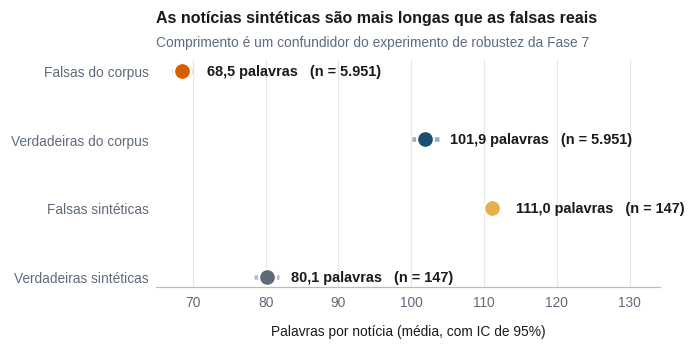

In [9]:
resumo = pd.read_csv(arquivo('metricas_sinteticas.csv'), index_col=0)
ordem = ['Falsas do corpus', 'Verdadeiras do corpus', 'Falsas sintéticas',
         'Verdadeiras sintéticas']
resumo = resumo.loc[[o for o in ordem if o in resumo.index]]
cores = {'Falsas do corpus': LARANJA, 'Verdadeiras do corpus': AZUL,
         'Falsas sintéticas': AMBAR, 'Verdadeiras sintéticas': SUAVE}

fig, ax = plt.subplots(figsize=(LARGURA, (3.6 + 0.8 * len(resumo)) * CM))
y = np.arange(len(resumo))
for i, (nome, linha) in enumerate(resumo.iterrows()):
    ic = 1.96 * linha['erro_padrao']
    ax.hlines(i, linha['media'] - ic, linha['media'] + ic,
              color=cores.get(nome, SUAVE), linewidth=3.0, alpha=0.45)
    ax.plot(linha['media'], i, 'o', markersize=11,
            color=cores.get(nome, SUAVE), markeredgecolor='white',
            markeredgewidth=1.4, zorder=4)
    ax.annotate(br('{:.1f}'.format(linha['media'])) + ' palavras   (n = '
                + mil(linha['n']) + ')',
                xy=(linha['media'], i), xytext=(16, 0),
                textcoords='offset points', ha='left', va='center',
                fontsize=T_ROTULO, fontweight='bold')

ax.set_yticks(y, resumo.index)
ax.invert_yaxis()
grade_x(ax)
ax.set_xlabel('Palavras por notícia (média, com IC de 95%)')
folga(ax, 'x', 0.42)
titulo(ax, 'As notícias sintéticas são mais longas que as falsas reais',
       'Comprimento é um confundidor do experimento de robustez da Fase 7')
salvar(fig, 'fig_sinteticas_tamanho')
plt.show()


## 9. Forma superficial: o corpus vem lematizado

Os autores do FakeRecogna distribuem o corpo das notícias já lematizado — daí termos como `umar`, `segundar` e `vezar`, que não são palavras do português corrente. As notícias sintéticas são português flexionado.

Isso não é detalhe de pré-processamento: um modelo treinado numa forma e avaliado em outra mede descasamento, não capacidade de detecção. A célula abaixo quantifica a diferença pela fração de tokens que já coincidem com o próprio lema, e verifica também se as duas classes do corpus recebem o mesmo tratamento — se não recebessem, a assinatura do processamento separaria as classes sozinha, o que seria um vazamento.

In [10]:
base_rotulo = pd.read_csv(arquivo('corpus_preparado.csv', 'corpus_base.csv'))
col_corpus = coluna(base_rotulo, 'texto', 'texto_limpo', 'noticia')

amostras = {
    'Corpus — Falsa':      base_rotulo.loc[base_rotulo['classe'] == 'Falsa', col_corpus],
    'Corpus — Verdadeira': base_rotulo.loc[base_rotulo['classe'] == 'Verdadeira', col_corpus],
    'Sintéticas — falsas': sint.loc[sint['rotulo'] == 1, col_texto],
}
if (sint['rotulo'] == 0).any():
    amostras['Sintéticas — verdadeiras'] = sint.loc[sint['rotulo'] == 0, col_texto]
taxas = pd.Series({nome: taxa_de_lema(serie.fillna('').astype(str))
                   for nome, serie in amostras.items()}, name='taxa_de_lema')
taxas.to_csv(DADOS / 'taxas_lematizacao.csv')

print(taxas.apply(lambda v: pct(v, 1)).to_string())
diferenca = 100 * (taxas['Corpus — Falsa'] - taxas['Corpus — Verdadeira'])
print('\ndiferença entre as classes do corpus:', br('{:+.2f}'.format(diferenca)), 'p.p.')
print('as duas classes recebem o mesmo tratamento'
      if abs(diferenca) < 8 else 'ATENÇÃO: pré-processamento assimétrico')


Corpus — Falsa              94,5%
Corpus — Verdadeira         91,1%
Sintéticas — falsas         60,4%
Sintéticas — verdadeiras    59,4%

diferença entre as classes do corpus: +3,43 p.p.
as duas classes recebem o mesmo tratamento


## 10. Versão lematizada do conjunto sintético

Aplica aos textos sintéticos o mesmo tipo de redução que o corpus recebeu. A Fase 7 avalia as duas versões: a natural mede o que acontece quando o modelo recebe texto do mundo real, e a lematizada mede a capacidade de detecção com as formas casadas.

In [11]:
sint['texto_lematizado'] = lematizar(sint[col_texto].fillna('').astype(str))

if 'rotulo' not in sint.columns:
    sint['rotulo'] = 1
    print('AVISO: conjunto sem coluna de rótulo; assumindo todas falsas.')
    print('Sem notícias verdadeiras não há como medir falso alarme: regere '
          'o conjunto na seção 6 para obter as duas classes.\n')

saida = sint[[col_texto, 'texto_lematizado', 'n_palavras', 'rotulo']].copy()
saida.columns = ['texto_sintetico', 'texto_lematizado', 'n_palavras', 'rotulo']
saida.to_csv(DADOS / 'sinteticas_processadas.csv', index=False)

print('gravadas {} notícias nas duas formas ({} falsas, {} verdadeiras)\n'
      .format(len(saida), int((saida['rotulo'] == 1).sum()),
              int((saida['rotulo'] == 0).sum())))
print('natural   :', ' '.join(saida['texto_sintetico'].iloc[0].split())[:110])
print('lematizado:', ' '.join(saida['texto_lematizado'].iloc[0].split())[:110])
print('corpus    :', ' '.join(str(amostras['Corpus — Falsa'].iloc[0]).split())[:110])


gravadas 294 notícias nas duas formas (147 falsas, 147 verdadeiras)

natural   : URGENTE: O governo espanhol acaba de confirmar o plano secreto para o fim do isolamento, mas o que eles escond
lematizado: URGENTE : o governo espanhol acabar de confirmar o plano secreto para o fim de o isolamento , mas o que eles e
corpus    : apagão vaticano papar presar acusação tráfico criança e fraude .. o papar francisco tuitou manhã o curador bea


## 11. Figura — taxa de lematização

Barras horizontais com a linha das duas classes do corpus próximas entre si e a das sintéticas destacada. A distância entre os dois blocos é o tamanho do descasamento que a Fase 7 vai medir.

[figura] fig_lematizacao.png            15.0 x 8.0 cm  (reduzida 5.3%)


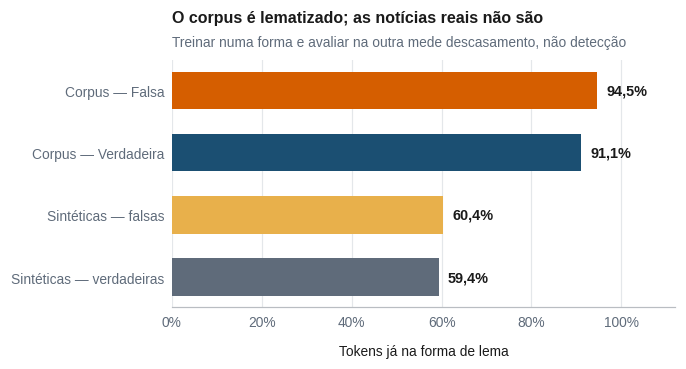

In [12]:
taxas = pd.read_csv(arquivo('taxas_lematizacao.csv'), index_col=0).iloc[:, 0]

paleta_lema = {'Corpus — Falsa': LARANJA, 'Corpus — Verdadeira': AZUL,
               'Sintéticas — falsas': AMBAR, 'Sintéticas — verdadeiras': SUAVE,
               'Sintéticas': AMBAR}
cores = [paleta_lema.get(n, SUAVE) for n in taxas.index]
fig, ax = plt.subplots(figsize=(LARGURA, (4.2 + 0.8 * len(taxas)) * CM))
y = np.arange(len(taxas))
barras = ax.barh(y, taxas.values, height=0.6, color=cores)
ax.set_yticks(y, taxas.index)
ax.invert_yaxis()
rotular_h(ax, barras, fmt='{:.1%}')
grade_x(ax)
ax.set_xlim(0, 1.0)
eixo_percentual(ax, 'x')
folga(ax, 'x', 0.12)
ax.set_xlabel('Tokens já na forma de lema')
titulo(ax, 'O corpus é lematizado; as notícias reais não são',
       'Treinar numa forma e avaliar na outra mede descasamento, não detecção')
salvar(fig, 'fig_lematizacao')
plt.show()
